In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'drive', 'sample_data']


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Untitled Diagram.drawio', 'Code (6)', 'Code (5)', 'Code (4)', 'Code (3)', 'Code (2)', 'Code (1)', 'Code', 'Crop Disease AI project', 'Member 05', 'class_distribution.png', 'IT25103052_Class_imbalance_handling.ipynb', 'IT25103052_class_distribution.png', 'IT25103052_class_weights.png', 'class_distribution.csv', 'class_weights.csv', 'Group_AIML']


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive/Group_AIML'))

['Member 05_IT25103052', '02_Group_Pipeline', '03_Final_Output', 'Member 02_IT25103229', 'Member 01_IT25103233', 'Member 03_IT25103371', 'Member 06_IT25103274', 'Member 04_IT25103567', 'Member 07_IT25103599 ', '01_Raw DataSet', '05_EDA Visualization', '06_Readme', '07_Notebooks', 'targeted_augmented_images']


In [ ]:
import os

MEMBER5_PATH = "/content/drive/MyDrive/Group_AIML/Member 05_IT25103052"

print(os.listdir(MEMBER5_PATH))

['Outputs', 'Notebook', 'EDA']


In [ ]:
import os

MEMBER7_OUTPUTS = "/content/drive/MyDrive/Group_AIML/Member 07_IT25103599 /Outputs"
MEMBER5_PATH = "/content/drive/MyDrive/Group_AIML/Member 05_IT25103052"

EDA_PATH = os.path.join(MEMBER5_PATH, "EDA")
OUTPUT_PATH = os.path.join(MEMBER5_PATH, "Outputs")

print("Member 7 Outputs:", MEMBER7_OUTPUTS)
print("Member 5 EDA:", EDA_PATH)
print("Member 5 Outputs:", OUTPUT_PATH)

Member 7 Outputs: /content/drive/MyDrive/Group_AIML/Member 07_IT25103599 /Outputs
Member 5 EDA: /content/drive/MyDrive/Group_AIML/Member 05_IT25103052/EDA
Member 5 Outputs: /content/drive/MyDrive/Group_AIML/Member 05_IT25103052/Outputs


In [ ]:
import pandas as pd

train_manifest = pd.read_csv(
    os.path.join(MEMBER7_OUTPUTS, "train_quality_manifest.csv")
)

augmented_manifest = pd.read_csv(
    os.path.join(MEMBER7_OUTPUTS, "augmented_quality_manifest.csv")
)

print("Original training images:", len(train_manifest))
print("Augmented images:", len(augmented_manifest))

Original training images: 11662
Augmented images: 3160


In [ ]:
original_counts = train_manifest["class"].value_counts()

print("Number of classes:", len(original_counts))
print("\nOriginal class distribution:")
print(original_counts)

Number of classes: 20

Original class distribution:
class
Brownspot                     1640
Becterial Blight in Rice      1584
Rice Blast                    1440
Tungro                        1308
Healthy Maize                 1162
RedRot sugarcane               592
Gray_Leaf_Spot                 574
Sugarcane Healthy              522
bacterial_blight in Cotton     489
Mosaic sugarcane               462
Healthy cotton                 425
Wilt                           419
Healthy Wheat                  180
Wheat Stem fly                 172
Wheat powdery mildew           169
Wheat black rust               161
maize fall armyworm            107
maize stem borer                95
cotton mealy bug                92
red cotton bug                  69
Name: count, dtype: int64


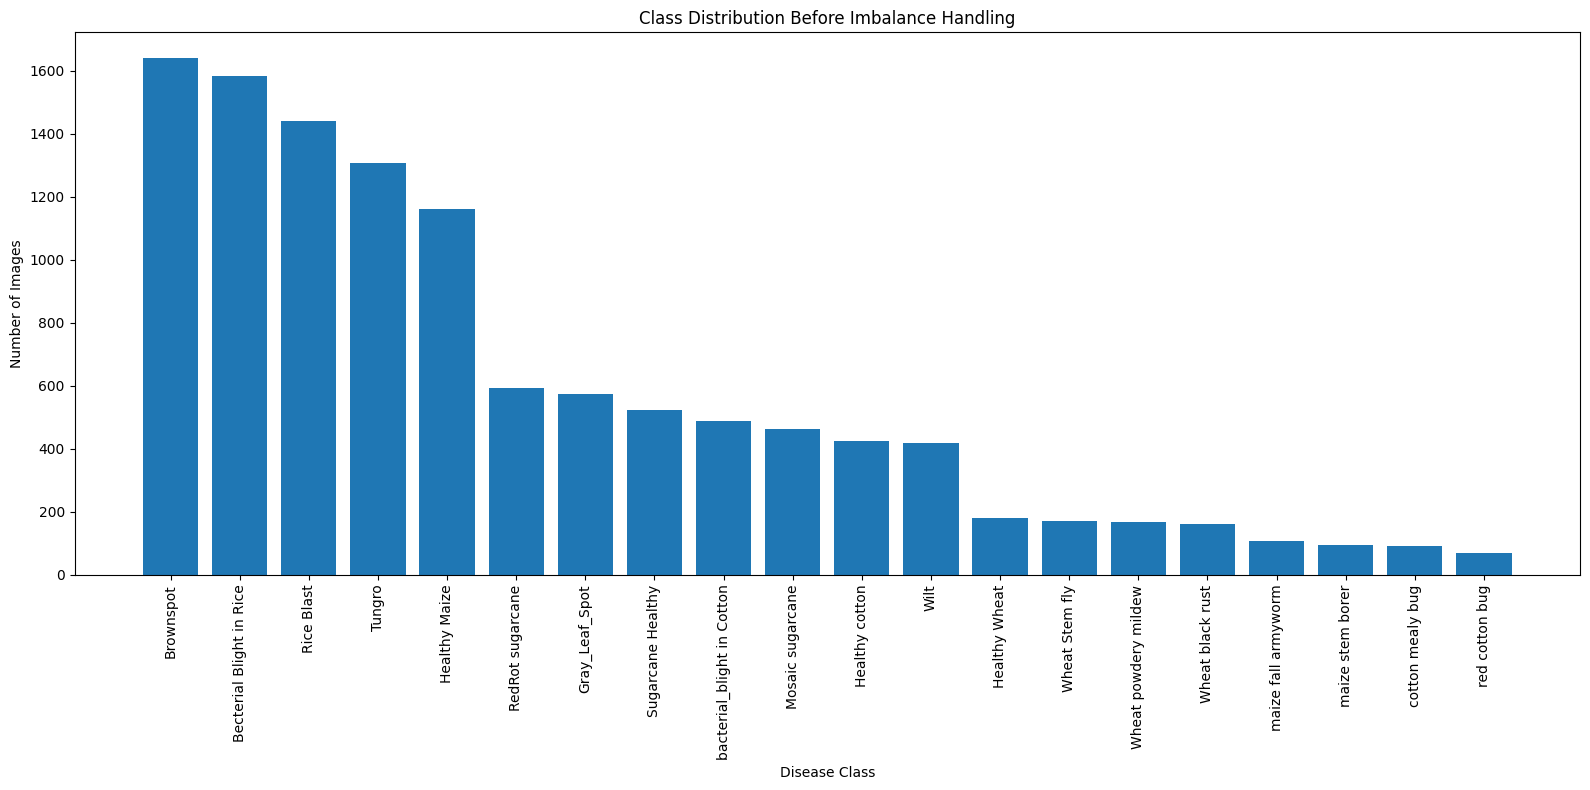

Saved to:
/content/drive/MyDrive/Group_AIML/Member 05_IT25103052/EDA/Class_Distribution_Before_Handling.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

plt.bar(
    original_counts.index,
    original_counts.values
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution Before Imbalance Handling")

plt.xticks(rotation=90)
plt.tight_layout()

# Save the graph in Member 5 → EDA
before_path = os.path.join(
    EDA_PATH,
    "Class_Distribution_Before_Handling.png"
)

plt.savefig(before_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:")
print(before_path)

In [ ]:
comparison = pd.DataFrame({
    "Original_Count": train_manifest["class"].value_counts(),
    "Augmented_Count": augmented_manifest["class"].value_counts()
}).fillna(0).astype(int)

comparison["Final_Count"] = (
    comparison["Original_Count"] +
    comparison["Augmented_Count"]
)

comparison = comparison.reset_index()

comparison = comparison.rename(
    columns={"index": "Class"}
)

print(comparison)

                         class  Original_Count  Augmented_Count  Final_Count
0     Becterial Blight in Rice            1584                0         1584
1                    Brownspot            1640                0         1640
2               Gray_Leaf_Spot             574                0          574
3                Healthy Maize            1162                0         1162
4                Healthy Wheat             180              320          500
5               Healthy cotton             425               75          500
6             Mosaic sugarcane             462               38          500
7             RedRot sugarcane             592                0          592
8                   Rice Blast            1440                0         1440
9            Sugarcane Healthy             522                0          522
10                      Tungro            1308                0         1308
11              Wheat Stem fly             172              328          500

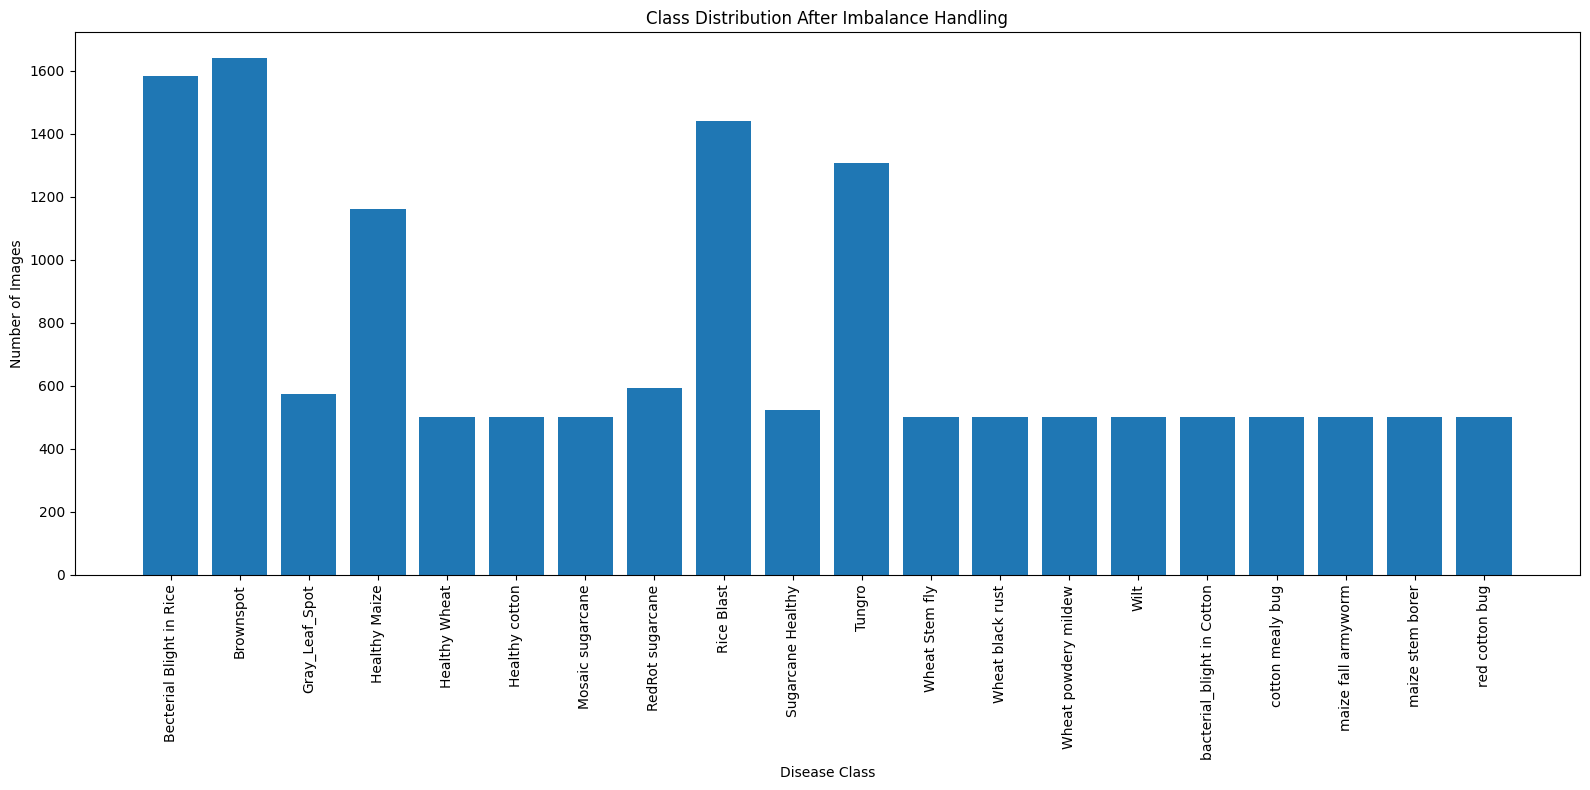

Saved to:
/content/drive/MyDrive/Group_AIML/Member 05_IT25103052/EDA/Class_Distribution_After_Handling.png


In [ ]:
plt.figure(figsize=(16, 8))

plt.bar(
    comparison["class"],
    comparison["Final_Count"]
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution After Imbalance Handling")

plt.xticks(rotation=90)
plt.tight_layout()

after_path = os.path.join(
    EDA_PATH,
    "Class_Distribution_After_Handling.png"
)

plt.savefig(after_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved to:")
print(after_path)

In [ ]:
results_path = os.path.join(
    OUTPUT_PATH,
    "Class_Imbalance_Handling_Results.csv"
)

comparison.to_csv(
    results_path,
    index=False
)

print("Results saved to:")
print(results_path)

Results saved to:
/content/drive/MyDrive/Group_AIML/Member 05_IT25103052/Outputs/Class_Imbalance_Handling_Results.csv


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = comparison["class"].values
final_counts = comparison["Final_Count"].values

final_labels = []

for cls, count in zip(classes, final_counts):
    final_labels.extend([cls] * count)

final_labels = np.array(final_labels)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=final_labels
)

class_weight_df = pd.DataFrame({
    "Class": classes,
    "Final_Count": final_counts,
    "Class_Weight": class_weights
})

print(class_weight_df)

                         Class  Final_Count  Class_Weight
0     Becterial Blight in Rice         1584      0.467866
1                    Brownspot         1640      0.451890
2               Gray_Leaf_Spot          574      1.291115
3                Healthy Maize         1162      0.637780
4                Healthy Wheat          500      1.482200
5               Healthy cotton          500      1.482200
6             Mosaic sugarcane          500      1.482200
7             RedRot sugarcane          592      1.251858
8                   Rice Blast         1440      0.514653
9            Sugarcane Healthy          522      1.419732
10                      Tungro         1308      0.566590
11              Wheat Stem fly          500      1.482200
12            Wheat black rust          500      1.482200
13        Wheat powdery mildew          500      1.482200
14                        Wilt          500      1.482200
15  bacterial_blight in Cotton          500      1.482200
16            